# Detecting events with volatility-scaled filters

This native Julia companion retains the original public minute records, strict event and barrier crossing rules, supplied-side construction, and trend-scan horizons. Explicit time vectors replace pandas indexes. Changing thresholds are aligned to available volatility observations before accumulation. Random first-passage checks use a local Xoshiro generator with seed 11; its draws differ from NumPy and are saved for independent replay. Figures use the requested dark theme, and outputs are saved under `outputs/julia`.

One-day price changes are converted to log returns, and recent squared deviations receive more weight in the volatility estimate:

$$
r_t^{(1d)}=\log P_t-\log P_{\ell(t)},\qquad
\widehat\sigma_t^2=\frac{\sum_{j=0}^{t}q^j\left(r_{t-j}^{(1d)}-\widehat\mu_t\right)^2}{\sum_{j=0}^{t}q^j},
\qquad q=1-\frac{2}{w+1}.
$$

Here, $P_t$ is price at time $t$; $\ell(t)$ is the latest recorded time strictly earlier than one day before $t.$ $r_t^{(1d)}$ is the one-day log return; $\widehat\mu_t$ is its weighted mean; $\widehat\sigma_t$ is estimated volatility. $q\in(0,1)$ is the decay factor; $w$ is the chosen span; $j$ counts how many observations back a return lies.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("06_financial_labels");
using CSV, Printf
using RiskLabAI.Data: daily_volatility_with_log_returns,symmetric_cusum_filter,cusum_filter_events_dynamic_threshold,vertical_barrier,triple_barrier,meta_labeling,calculate_t_value_linear_regression,find_trend_using_trend_scanning
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
close_index,close_prices = raw.time,raw.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
violet = "#C084FC"

function count_histogram!(figure,values,bins;color,label=false,alpha=.75)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    counts = [count(value->edges[index]<=value && (value<edges[index+1] || index==bins && value==edges[end]),values) for index in 1:bins]
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,counts;bar_width=diff(edges),color,fillalpha=alpha,linecolor=color,label)
    ylims!(figure,0.,1.1max(maximum(counts),last(ylims(figure))))
    return DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts)
end

function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end


box_summary! (generic function with 1 method)

## Scaling one-day changes by volatility

9×2 DataFrame
 Row │ Field           Value
     │ String          String
─────┼───────────────────────────────────────────────────
   1 │ Archive         BTCUSDT-1m-2021-01.zip
   2 │ Provider        Binance Data Vision
   3 │ Public access   Direct public download
   4 │ Market          Bitcoin quoted in USDT
   5 │ Sample start    2021-01-01T00:00:00
   6 │ Sample end      2021-01-31T23:59:00
   7 │ Records         44640
   8 │ Interval        One minute

Row,Quantity,Summary,Value
,String,String,Float64
1,One-day log return,Standard deviation,0.0657196
2,Estimated volatility,10th percentile,0.00600402
3,Estimated volatility,Middle value,0.0106997
4,Estimated volatility,90th percentile,0.0197456


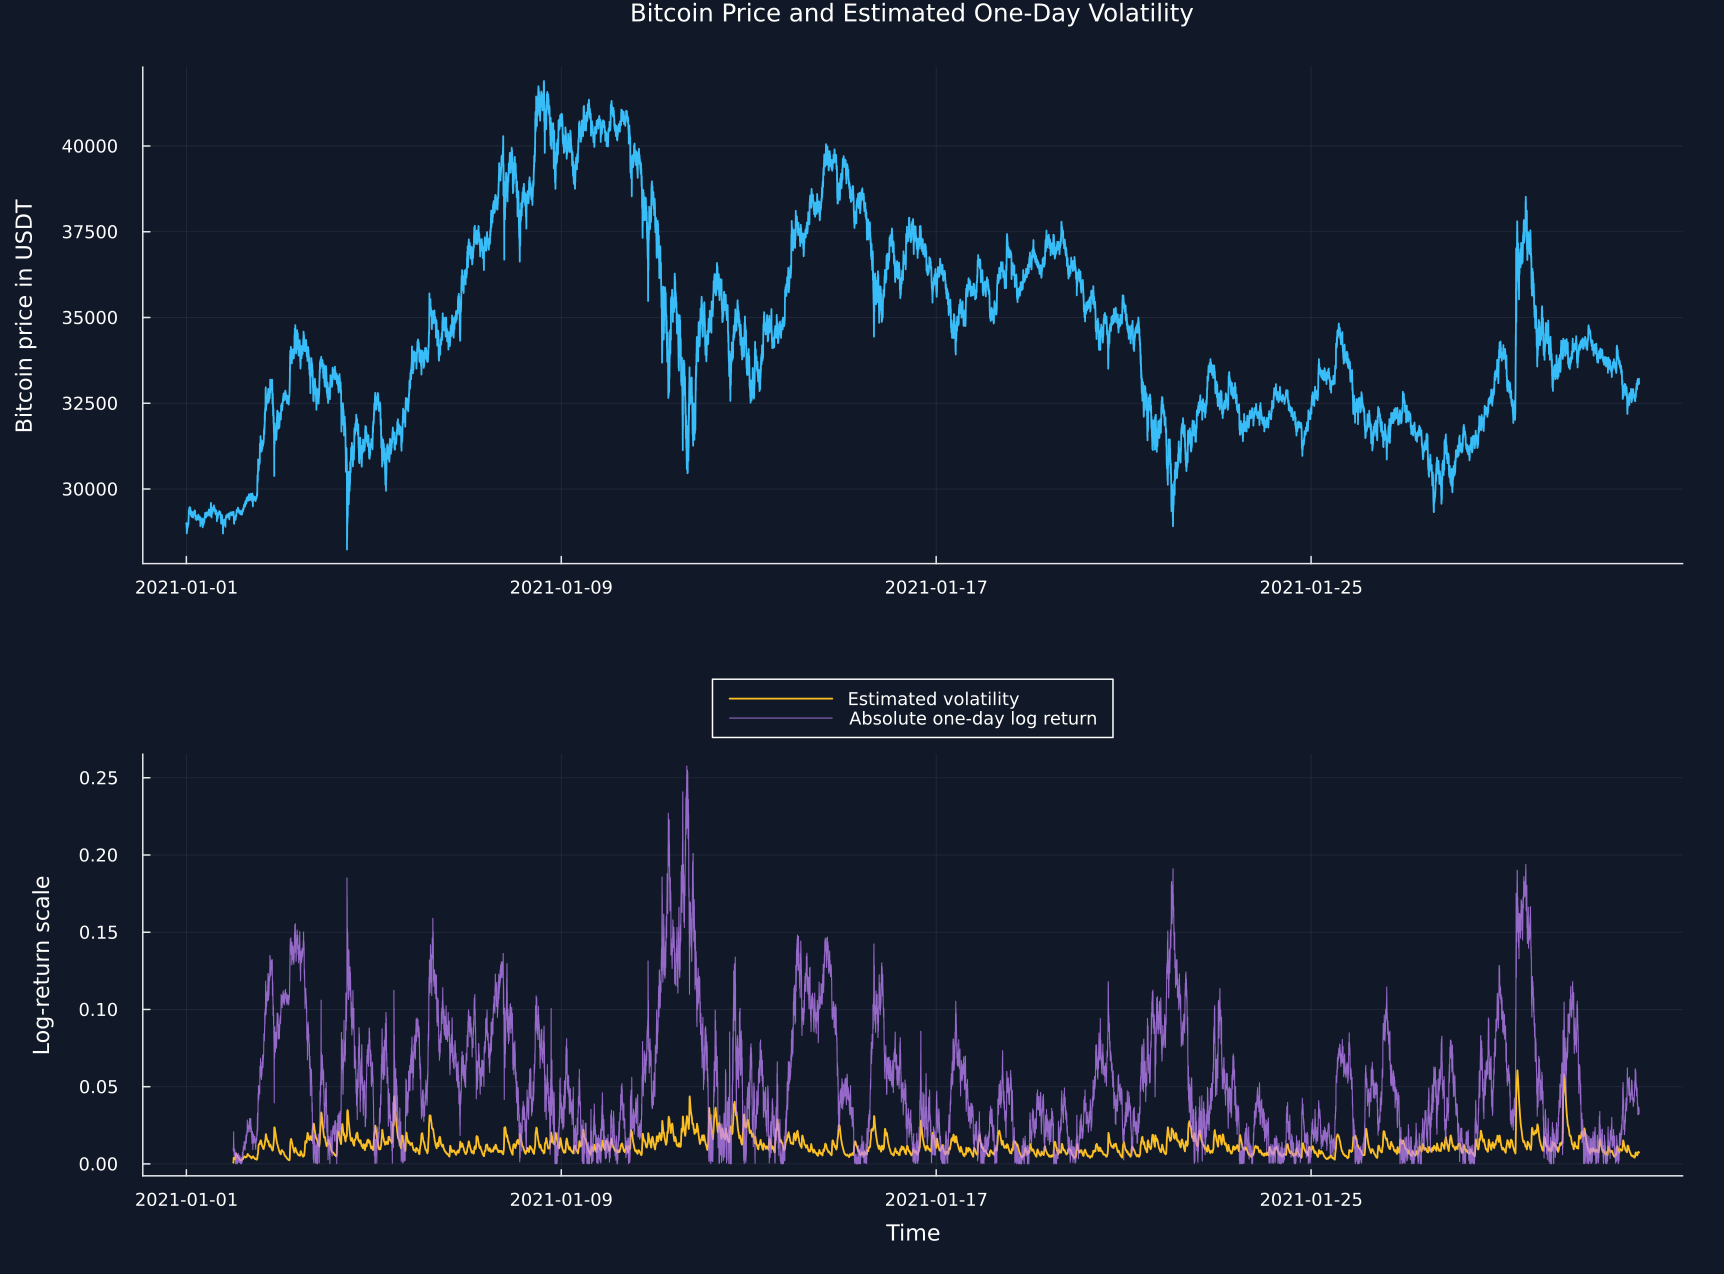

In [2]:
span = 100
volatility = daily_volatility_with_log_returns(close_index,close_prices;span)
volatility_lookup = Dict(zip(volatility.index,volatility.volatility))

function dynamic_threshold_events(multiplier)
    selected = findall(isfinite,volatility.volatility)
    positions = [price_positions[volatility.index[index]] for index in selected]
    aligned = vcat(first(positions)-1,positions)
    return cusum_filter_events_dynamic_threshold(close_index[aligned],log_price[aligned],vcat(NaN,multiplier.*volatility.volatility[selected]))
end
prior_positions = [searchsortedfirst(close_index,time-Day(1))-1 for time in volatility.index]
current_positions = [price_positions[time] for time in volatility.index]
one_day_return = log.(close_prices[current_positions]./close_prices[prior_positions])
function independent_ewm_std(values,span)
    decay = 1-2/(span+1)
    mass,mass_squared,average,scatter = 0.,0.,0.,0.
    result = fill(NaN,length(values))
    for (index,value) in enumerate(values)
        mass = decay*mass+1
        mass_squared = decay^2*mass_squared+1
        difference = value-average
        average += difference/mass
        scatter = decay*scatter+difference*(value-average)
        denominator = mass^2-mass_squared
        denominator>0 && (result[index]=sqrt(max(0.,scatter*mass/denominator)))
    end
    return result
end
independent_volatility = independent_ewm_std(one_day_return,span)
data_provenance = DataFrame("Field"=>["Archive","Provider","Public access","Market","Sample start","Sample end","Records","Interval"],"Value"=>["BTCUSDT-1m-2021-01.zip","Binance Data Vision","Direct public download","Bitcoin quoted in USDT",string(first(close_index)),string(last(close_index)),string(length(close_prices)),"One minute"])
finite_volatility = filter(isfinite,volatility.volatility)
volatility_summary = DataFrame("Quantity"=>["One-day log return","Estimated volatility","Estimated volatility","Estimated volatility"],"Summary"=>["Standard deviation","10th percentile","Middle value","90th percentile"],"Value"=>[std(one_day_return),quantile(finite_volatility,.1),median(finite_volatility),quantile(finite_volatility,.9)])
save_table(data_provenance,paths,"data_provenance";caption="Public data used for the Chapter 5 experiments.",label="tab:chapter5-data-provenance")
save_table(volatility_summary,paths,"volatility_summary";caption="One-day return and volatility summaries for the 31-day sample.",label="tab:volatility-summary")
save_data(DataFrame(time=volatility.index,prior_time=close_index[prior_positions],one_day_return=one_day_return,volatility=volatility.volatility,independent_volatility=independent_volatility),paths,"volatility_path")
p1 = plot(close_index,close_prices;color=palette.cyan,linewidth=1.2,ylabel="Bitcoin price in USDT",title="Bitcoin Price and Estimated One-Day Volatility",label=false)
p2 = plot(volatility.index,volatility.volatility;color=palette.amber,linewidth=1.2,ylabel="Log-return scale",xlabel="Time",label="Estimated volatility",legend=:outertop)
plot!(p2,volatility.index,abs.(one_day_return);color=violet,linewidth=.7,alpha=.75,label="Absolute one-day log return")
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1150,850)),paths,"price_and_volatility")


## Symmetric Cumulative Filter

Positive and negative movements accumulate separately, while movement in the opposite direction pulls each total back toward zero:

$$
S_t^+=\max\{0,S_{t-1}^++\Delta x_t\},\qquad
S_t^-=\min\{0,S_{t-1}^-+\Delta x_t\},\qquad
\Delta x_t=x_t-x_{t-1}.
$$

Here, $x_t$ is the measured series at time $t$; $\Delta x_t$ is its one-step change. $S_t^+\geq0$ is the positive cumulative total; $S_t^-\leq0$ is the negative cumulative total; both start at zero.

In [3]:
fixed_threshold,dynamic_multiplier = .02,2.
fixed_events = symmetric_cusum_filter(close_index,log_price,fixed_threshold)
dynamic_events = dynamic_threshold_events(dynamic_multiplier)
sensitivity_records = NamedTuple[]
for level in [.01,.02,.03]
    selected = symmetric_cusum_filter(close_index,log_price,level)
    gaps = Dates.value.(diff(selected))./60000
    push!(sensitivity_records,(;rule="Fixed log-price change",level,events=length(selected),gap=median(gaps)))
end
for multiplier in [1.,1.5,2.]
    selected = dynamic_threshold_events(multiplier)
    gaps = Dates.value.(diff(selected))./60000
    push!(sensitivity_records,(;rule="Multiple of estimated volatility",level=multiplier,events=length(selected),gap=median(gaps)))
end
threshold_sensitivity = DataFrame(sensitivity_records)
rename!(threshold_sensitivity,["Threshold rule","Threshold level","Events","Middle gap in minutes"])
sample_days = length(unique(Date.(close_index)))
event_summary = DataFrame("Rule"=>["Fixed threshold","Changing threshold"],"Chosen level"=>["0.020 log-price units","2.0 times estimated volatility"],"Events"=>[length(fixed_events),length(dynamic_events)],"Events per day"=>[length(fixed_events),length(dynamic_events)]./sample_days)
save_table(event_summary,paths,"event_filter_summary";caption="Event counts under fixed and changing cumulative thresholds.",label="tab:event-filter-summary")
save_table(threshold_sensitivity,paths,"event_threshold_sensitivity";caption="Event counts and waiting times across threshold choices.",label="tab:event-threshold-sensitivity")
save_data(DataFrame(time=fixed_events),paths,"fixed_event_times")
save_data(DataFrame(time=dynamic_events),paths,"dynamic_event_times");


Row,Rule,Chosen level,Events,Events per day
,String,String,Int64,Float64
1,Fixed threshold,0.020 log-price units,643,20.7419
2,Changing threshold,2.0 times estimated volatility,540,17.4194


Row,Threshold rule,Threshold level,Events,Middle gap in minutes
,String,Float64,Int64,Float64
1,Fixed log-price change,0.01,2005,15.0
2,Fixed log-price change,0.02,643,45.0
3,Fixed log-price change,0.03,322,103.0
4,Multiple of estimated volatility,1.0,1705,18.0
5,Multiple of estimated volatility,1.5,869,37.0
6,Multiple of estimated volatility,2.0,540,64.0


## First Crossings

Event $k$ occurs at the first time either cumulative total passes its current threshold:

$$
\tau_k=\inf\{t>\tau_{k-1}:S_t^+>h_t\ \text{or}\ S_t^-<-h_t\}.
$$

Here, $\tau_k$ is the time of event $k$; $\tau_{k-1}$ is the preceding event time; $t$ is a candidate time. $S_t^+$ and $S_t^-$ are the positive and negative totals; $h_t>0$ is the fixed or changing threshold; $\inf$ selects the first crossing.

Row,Direction,Crossings,Smallest excess
,String,Int64,Float64
1,Positive,320,9.22453e-7
2,Negative,323,1.32013e-5
3,All,643,9.22453e-7


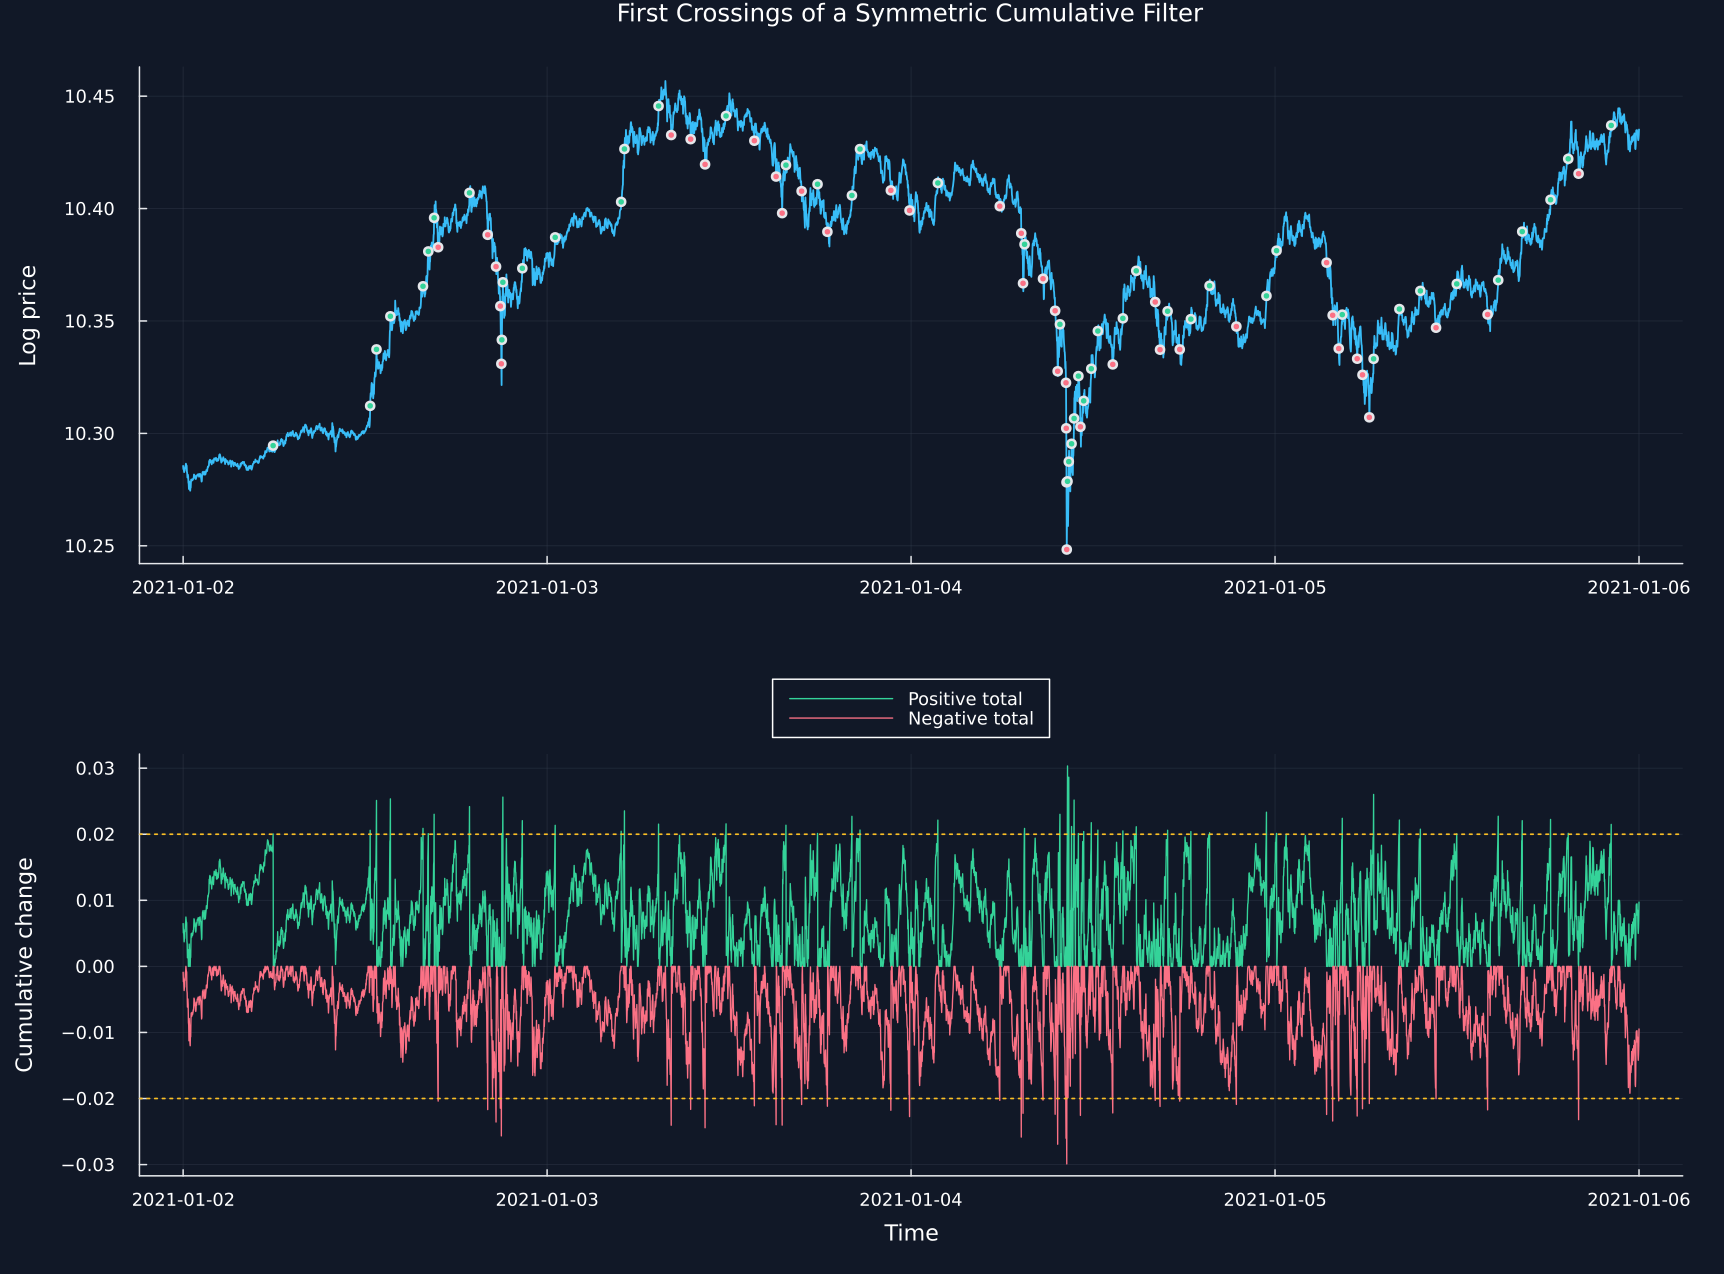

In [4]:
function cumulative_trace(times,values,threshold)
    positive,negative = 0.,0.
    rows = NamedTuple[]
    for index in 2:length(values)
        change = values[index]-values[index-1]
        positive_before,negative_before = max(0.,positive+change),min(0.,negative+change)
        direction = 0
        positive,negative = positive_before,negative_before
        if negative_before < -threshold
            direction,negative = -1,0.
        elseif positive_before > threshold
            direction,positive = 1,0.
        end
        push!(rows,(;time=times[index],change,positive_before,negative_before,positive_after=positive,negative_after=negative,direction))
    end
    return DataFrame(rows)
end
trace = cumulative_trace(close_index,log_price,fixed_threshold)
crossings = trace[trace.direction.!=0,:]
positive_excess = crossings.positive_before[crossings.direction.==1].-fixed_threshold
negative_excess = -crossings.negative_before[crossings.direction.==-1].-fixed_threshold
first_crossing_check = DataFrame("Direction"=>["Positive","Negative","All"],"Crossings"=>[count(==(1),crossings.direction),count(==(-1),crossings.direction),nrow(crossings)],"Smallest excess"=>[minimum(positive_excess),minimum(negative_excess),minimum(vcat(positive_excess,negative_excess))])
save_table(first_crossing_check,paths,"cusum_first_crossing_check";caption="Checks of strict first crossings under the fixed cumulative threshold.",label="tab:cusum-first-crossing")
save_data(trace,paths,"fixed_cusum_trace")
view_start,view_end = close_index[1441],close_index[7201]
visible = trace[view_start .<= trace.time .<= view_end,:]
view_events = crossings[view_start .<= crossings.time .<= view_end,:]
p1 = plot(close_index[1441:7201],log_price[1441:7201];color=palette.cyan,linewidth=1.2,ylabel="Log price",title="First Crossings of a Symmetric Cumulative Filter",label=false)
scatter!(p1,view_events.time,[log_price[price_positions[time]] for time in view_events.time];markercolor=ifelse.(view_events.direction.>0,palette.green,palette.rose),markersize=3,label=false)
p2 = plot(visible.time,visible.positive_before;color=palette.green,linewidth=.9,label="Positive total",ylabel="Cumulative change",xlabel="Time",legend=:outertop)
plot!(p2,visible.time,visible.negative_before;color=palette.rose,linewidth=.9,label="Negative total")
hline!(p2,[fixed_threshold,-fixed_threshold];color=palette.amber,linestyle=:dot,linewidth=1.1,label=false)
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1150,850)),paths,"cusum_first_crossings")


## Changing-Threshold Event Map

Row,Quantity,Value
,String,Float64
1,Events,540.0
2,Positive event changes,274.0
3,Negative event changes,266.0
4,Middle absolute event change,0.00279506
5,90th percentile absolute event change,0.00658348


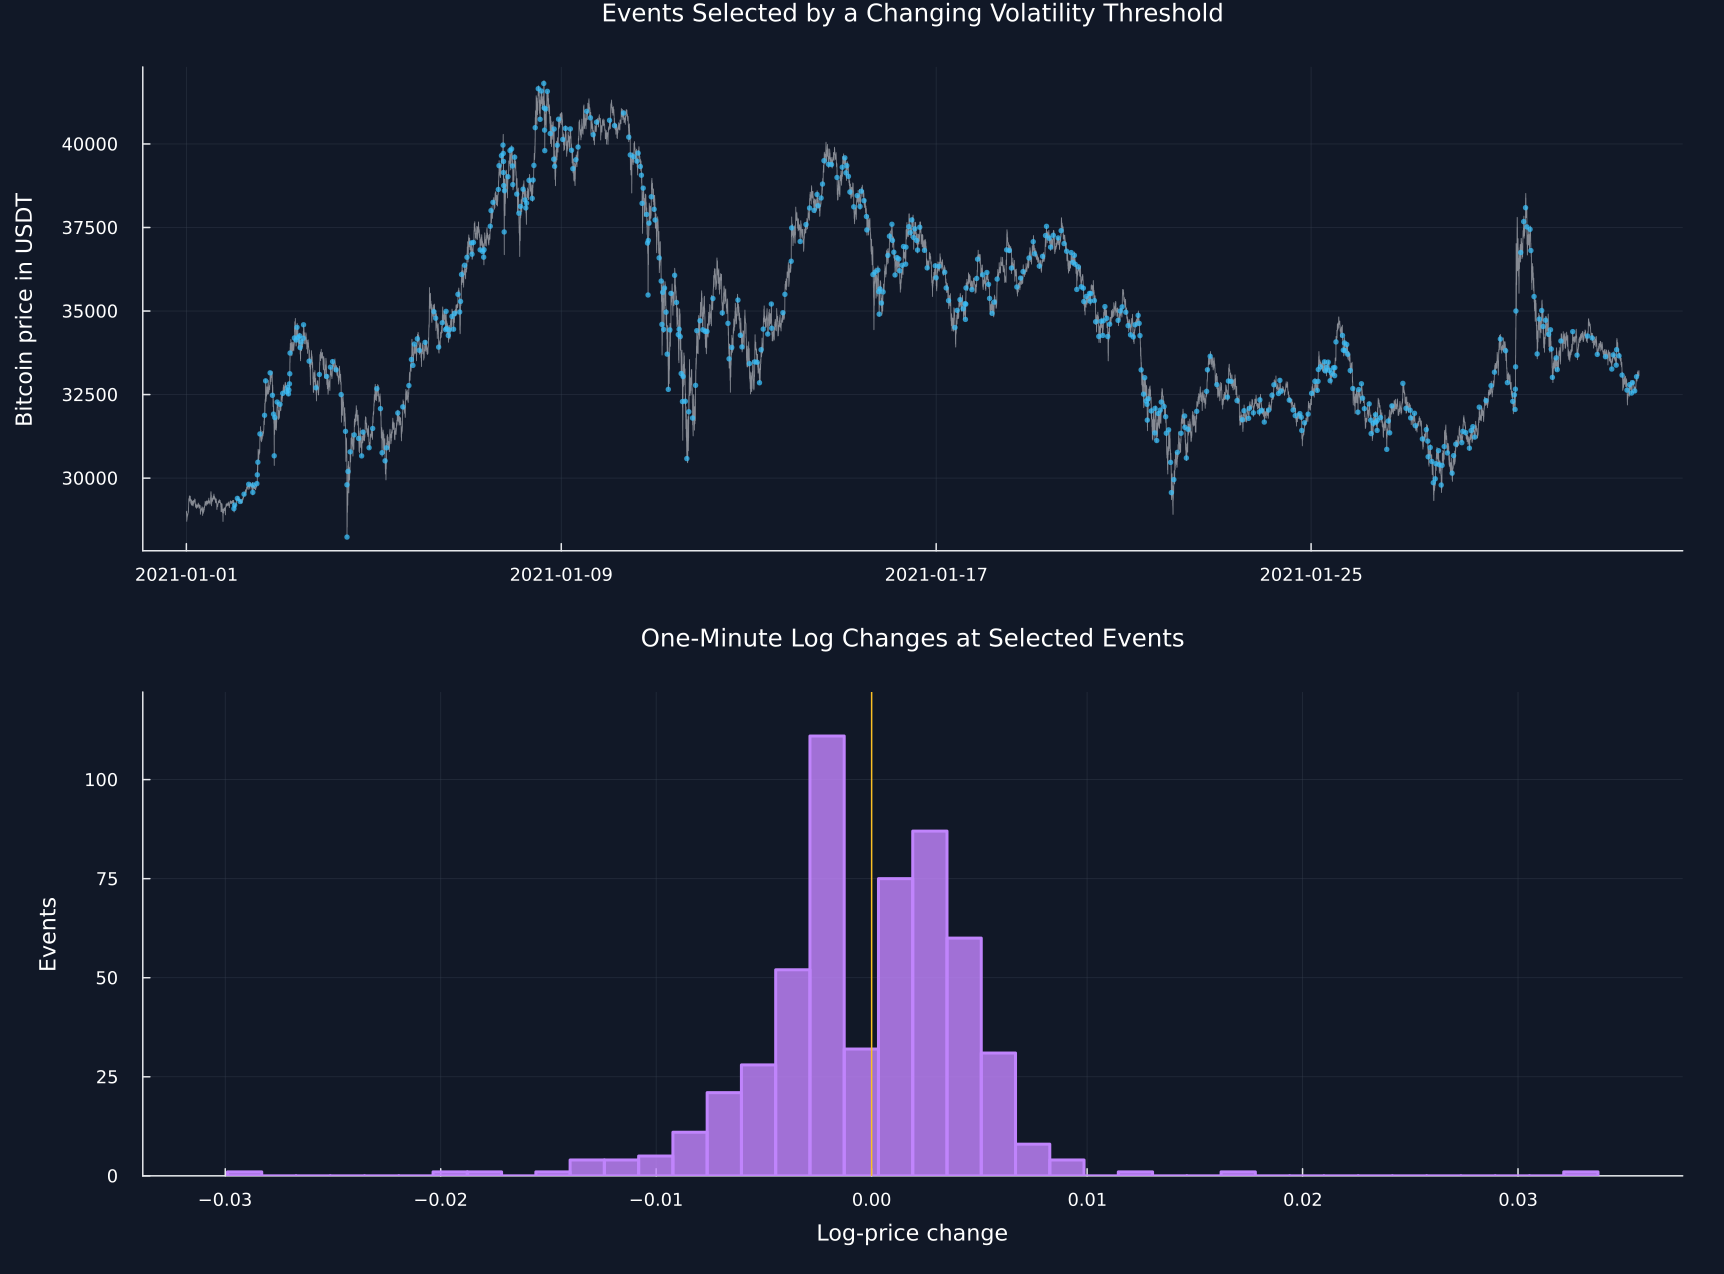

In [5]:
dynamic_positions = [price_positions[time] for time in dynamic_events]
dynamic_event_changes = log_price[dynamic_positions].-log_price[dynamic_positions.-1]
dynamic_event_summary = DataFrame("Quantity"=>["Events","Positive event changes","Negative event changes","Middle absolute event change","90th percentile absolute event change"],"Value"=>[length(dynamic_events),count(>(0),dynamic_event_changes),count(<(0),dynamic_event_changes),median(abs.(dynamic_event_changes)),quantile(abs.(dynamic_event_changes),.9)])
save_table(dynamic_event_summary,paths,"dynamic_event_summary";caption="Events selected by the changing volatility threshold.",label="tab:chapter5-dynamic-events")
p1 = plot(close_index,close_prices;color=palette.text,linewidth=.55,alpha=.55,title="Events Selected by a Changing Volatility Threshold",ylabel="Bitcoin price in USDT",label=false)
scatter!(p1,dynamic_events,close_prices[dynamic_positions];color=palette.cyan,markersize=2,alpha=.75,markerstrokewidth=0,label=false)
p2 = plot(;title="One-Minute Log Changes at Selected Events",xlabel="Log-price change",ylabel="Events",legend=false)
histogram_data = count_histogram!(p2,dynamic_event_changes,40;color=violet,alpha=.82)
vline!(p2,[0.];color=palette.amber,linewidth=1.,label=false)
save_data(histogram_data,paths,"dynamic_event_histogram")
save_figure(plot(p1,p2;layout=(2,1),size=(1150,850)),paths,"dynamic_cusum_events")


## Tests

In [6]:
controlled_dates = collect(DateTime(2020,1,1):Day(1):DateTime(2020,1,20))
controlled_prices = Float64[10,11,12,13,14,15,14,13,12,11,10,11,12,11,12,11,12,13,14,15]
@assert symmetric_cusum_filter(controlled_dates,controlled_prices,3.) == DateTime.(2020,1,[5,10,19])
@assert isnan(first(volatility.volatility)) && isnan(first(independent_volatility))
@assert isapprox(volatility.volatility[2:end],independent_volatility[2:end];rtol=1e-10,atol=1e-12)
@assert fixed_events == crossings.time
@assert length(close_prices) == 44640
@assert issorted(close_index)
@assert allunique(close_index)
@assert all(close_prices.>0)
@assert all(filter(isfinite,volatility.volatility).>0)
@assert !isempty(fixed_events)
@assert !isempty(dynamic_events)
@assert sample_days == 31
@assert all(positive_excess.>0)
@assert all(negative_excess.>0)
@assert issorted(threshold_sensitivity[1:3,"Events"];rev=true)
@assert issorted(threshold_sensitivity[4:6,"Events"];rev=true)
@assert dynamic_event_summary.Value[1] == length(dynamic_events)
@assert length(dynamic_event_changes) == length(dynamic_events)
@assert isfile(joinpath(paths.figures,"dynamic_cusum_events.pdf"))
@assert isfile(joinpath(paths.tables,"dynamic_event_summary.tex"))
